# StyleBot — Entrega 3: Integración de Percepción CNN con el Entorno RL

**Responsable:** Juan José Aranda Flores  
**Rol:** Responsable de redes neuronales CNN  
**Protocolo utilizado:** `datos/entrega3/protocolo_entrega3.json` (`entrega3-1.0`)  
**Modelo de percepción congelado:** `modelos/stylebot_cnn_final.keras` (sin reentrenamiento ni modificación)

**Objetivos de este notebook:**
1. Cargar el módulo `src/entrega3/percepcion_cnn.py` y comprobar el funcionamiento de la CNN congelada sobre imágenes de $28 \times 28$.
2. Seleccionar de forma reproducible 50 prendas de Fashion-MNIST (`semilla_demo = 2026`), predecir su categoría y confianza, y exportar `datos/entrega3/predicciones_50_prendas.csv`.
3. Conectar la percepción de la CNN con el entorno del almacén `AlmacenStyleBot` (`src/entrega3/entorno_almacen.py`), verificando que la categoría predicha determine el estante objetivo.
4. Identificar, marcar, visualizar y explicar los errores de la CNN (`prediccion != etiqueta_real`) y su impacto en la recompensa del almacén.

In [1]:
!pip install -q gymnasium

import os
import sys
import json
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

REPO_URL = "https://github.com/krysto9872/StyleBot.git"
REPO_DIR = "/content/StyleBot"

if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)

subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.entrega3.percepcion_cnn import (
    cargar_protocolo,
    cargar_modelo_cnn,
    predecir_prenda,
    obtener_estante_objetivo,
    generar_csv_predicciones_50,
)
from src.entrega3.entorno_almacen import (
    AlmacenStyleBot,
    CATEGORIAS,
    ESTANTES,
    MOVIMIENTOS,
    TOMAR,
    COLOCAR,
    SIN_CARGA,
)

protocolo = cargar_protocolo("datos/entrega3/protocolo_entrega3.json")
modelo_cnn = cargar_modelo_cnn(protocolo["modelo_cnn"])

print("Protocolo cargado:", protocolo["version"])
print("Semilla demo:", protocolo["semilla_demo"], "| Prendas demo:", protocolo["prendas_demo"])
print("Modelo CNN congelado (trainable):", modelo_cnn.trainable)
print("Entrada esperada por la CNN:", modelo_cnn.input_shape)

Protocolo cargado: entrega3-1.0
Semilla demo: 2026 | Prendas demo: 50
Modelo CNN congelado (trainable): False
Entrada esperada por la CNN: (None, 28, 28, 1)


## 1. Validación del módulo `percepcion_cnn.py` con imágenes de $28 \times 28$

Se comprueba que la función `predecir_prenda` reciba imágenes de $28 \times 28$ (tanto normalizadas en `[0, 1]` como en `[0, 255]` sin volver a dividir dos veces) y devuelva la categoría predicha, la confianza y el estante objetivo correspondiente.

In [2]:
# Generar el CSV oficial de las 50 prendas usando semilla_demo = 2026
ruta_csv = "datos/entrega3/predicciones_50_prendas.csv"
df_50, imagenes_50, etiquetas_50, predicciones_50 = generar_csv_predicciones_50(
    modelo=modelo_cnn,
    ruta_salida=ruta_csv,
)

# Comprobar función individual con una imagen 28x28 en [0, 1] y su equivalente en [0, 255]
ejemplo_01 = imagenes_50[0]
ejemplo_255 = (ejemplo_01 * 255.0).astype(np.uint8)

res_01 = predecir_prenda(modelo_cnn, ejemplo_01, protocolo)
res_255 = predecir_prenda(modelo_cnn, ejemplo_255, protocolo)

assert res_01["categoria_id"] == res_255["categoria_id"]
print("Prueba unitaria exitosa (imagen 28x28):")
print(f"  Etiqueta real:     {etiquetas_50[0]} ({CATEGORIAS[etiquetas_50[0]]})")
print(f"  Predicción CNN:    {res_01['categoria_id']} ({res_01['categoria']})")
print(f"  Confianza:         {res_01['confianza']:.4f}")
print(f"  Estante objetivo:  {res_01['estante_objetivo']}")

total_prendas = len(df_50)
total_errores = int(df_50["es_error"].sum())
total_aciertos = total_prendas - total_errores
exactitud_50 = total_aciertos / total_prendas

print(f"\nArchivo guardado en: {ruta_csv}")
print(f"Resumen 50 prendas -> Aciertos: {total_aciertos}/50 | Errores CNN: {total_errores}/50 | Exactitud: {exactitud_50:.4f}")
display(df_50.head(15))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Prueba unitaria exitosa (imagen 28x28):
  Etiqueta real:     2 (Suéter)
  Predicción CNN:    2 (Suéter)
  Confianza:         0.7519
  Estante objetivo:  (0, 2)

Archivo guardado en: datos/entrega3/predicciones_50_prendas.csv
Resumen 50 prendas -> Aciertos: 49/50 | Errores CNN: 1/50 | Exactitud: 0.9800


,id_prenda,indice_test,etiqueta_real,categoria_real,prediccion,categoria_predicha,confianza,es_error,estante_real,estante_objetivo
0,0,2908,2,Suéter,2,Suéter,0.751858,False,"(0, 2)","(0, 2)"
1,1,4811,5,Sandalia,5,Sandalia,0.999904,False,"(0, 5)","(0, 5)"
2,2,6353,3,Vestido,3,Vestido,0.977392,False,"(0, 3)","(0, 3)"
3,3,1303,3,Vestido,3,Vestido,0.999700,False,"(0, 3)","(0, 3)"
4,4,129,5,Sandalia,5,Sandalia,1.000000,False,"(0, 5)","(0, 5)"
5,5,9585,2,Suéter,2,Suéter,0.994215,False,"(0, 2)","(0, 2)"
6,6,7051,9,Botín,9,Botín,0.999980,False,"(4, 7)","(4, 7)"
7,7,836,2,Suéter,2,Suéter,0.986854,False,"(0, 2)","(0, 2)"
8,8,9098,1,Pantalón,1,Pantalón,1.000000,False,"(0, 1)","(0, 1)"
9,9,7364,3,Vestido,3,Vestido,0.989505,False,"(0, 3)","(0, 3)"


## 2. Integración de la percepción CNN con el entorno `AlmacenStyleBot`

Se instancia el entorno `AlmacenStyleBot` (creado por Luis Ángel en `src/entrega3/entorno_almacen.py`) pasando `etiquetas=etiquetas_50` (categorías reales) y `predicciones=predicciones_50` (categorías percibidas por la CNN).

Para probar la integración de extremo a extremo de forma determinista:
1. El robot toma cada prenda en la recepción `(7, 3)` y recibe del entorno únicamente `carga_percibida` (la predicción de la CNN).
2. Esa categoría predicha determina el estante objetivo `entorno.posicion_estante[carga_percibida]`.
3. Se navega por el camino más corto usando `entorno.distancias_desde(...)` para depositar la prenda en el estante objetivo (o devolverla a recepción si ese estante estuviera lleno).
4. El entorno calcula la recompensa real (`+10` si el estante coincide con la etiqueta real, `-8` si difiere y registrando el evento en `fallos_cnn`).

In [3]:
def elegir_accion_navegacion(entorno: AlmacenStyleBot, destino: tuple[int, int]) -> int:
    """Selecciona el siguiente paso más corto desde la posición actual hasta `destino`."""
    distancias = entorno.distancias_desde(destino)
    pos_actual = entorno.posicion
    mejor_accion = 0
    mejor_dist = distancias[pos_actual]

    for accion, (df, dc) in MOVIMIENTOS.items():
        vecino = (pos_actual[0] + df, pos_actual[1] + dc)
        if vecino in distancias and distancias[vecino] < mejor_dist:
            mejor_dist = distancias[vecino]
            mejor_accion = accion
    return mejor_accion


def ejecutar_integracion(entorno: AlmacenStyleBot, indices_episodio: np.ndarray, semilla: int = 2026):
    """Ejecuta un episodio completo conectando las predicciones CNN con AlmacenStyleBot."""
    obs, info = entorno.reset(seed=semilla, options={"indices": indices_episodio})
    terminado = False
    truncado = False
    recompensa_total = 0.0
    registros_entrega = []

    while not (terminado or truncado):
        fila, col, carga, destino_lleno = entorno.decodificar(obs)

        if carga == SIN_CARGA:
            # Ir a recepción y tomar la siguiente prenda
            if (fila, col) in entorno.recepcion:
                accion = TOMAR
            else:
                accion = elegir_accion_navegacion(entorno, entorno.inicio)
        else:
            # La categoría predicha por la CNN determina el estante objetivo
            if destino_lleno:
                # Si el estante objetivo está lleno, volver a recepción y devolver
                if (fila, col) in entorno.recepcion:
                    accion = COLOCAR
                else:
                    accion = elegir_accion_navegacion(entorno, entorno.inicio)
            else:
                estante_obj = entorno.posicion_estante[carga]
                if (fila, col) == estante_obj:
                    accion = COLOCAR
                else:
                    accion = elegir_accion_navegacion(entorno, estante_obj)

        carga_real_antes = info["carga_real"]
        carga_perc_antes = info["carga_percibida"]

        obs, recompensa, terminado, truncado, info = entorno.step(accion)
        recompensa_total += recompensa

        if info["evento"] in ("correcto", "incorrecto", "devuelta"):
            registros_entrega.append(
                {
                    "paso": info["pasos"],
                    "evento": info["evento"],
                    "etiqueta_real": carga_real_antes,
                    "categoria_real": CATEGORIAS[carga_real_antes],
                    "prediccion_cnn": carga_perc_antes,
                    "categoria_predicha": CATEGORIAS[carga_perc_antes],
                    "estante_destino": entorno.posicion_estante[carga_perc_antes],
                    "recompensa_entrega": recompensa,
                }
            )

    return recompensa_total, terminado, truncado, info, pd.DataFrame(registros_entrega)


# Crear entorno con los parámetros del protocolo
entorno_50 = AlmacenStyleBot(
    etiquetas=etiquetas_50,
    predicciones=predicciones_50,
    prendas_por_episodio=protocolo["prendas_demo"],
    capacidad=8,
    max_pasos=protocolo["prendas_demo"] * protocolo["max_pasos_por_prenda"],
    recompensas=protocolo["recompensas"],
    render_mode="ansi",
)

recompensa_total, terminado, truncado, info_final, df_entregas = ejecutar_integracion(
    entorno_50,
    indices_episodio=np.arange(len(etiquetas_50)),
    semilla=protocolo["semilla_demo"],
)

print("=== RESULTADO DE LA INTEGRACIÓN CNN -> ALMACÉN (50 PRENDAS) ===")
print(f"Terminado: {terminado} | Truncado: {truncado}")
print(f"Pasos totales:         {info_final['pasos']}")
print(f"Recompensa acumulada:  {recompensa_total:.1f}")
print(f"Colocaciones correctas:{info_final['correctas']}/50")
print(f"Colocaciones erróneas: {info_final['incorrectas']}/50")
print(f"  -> Fallos de CNN:    {info_final['fallos_cnn']}")
print(f"  -> Fallos política:  {info_final['fallos_politica']}")
print(f"Acciones inválidas:    {info_final['acciones_invalidas']}")
print(f"Ocupación por estante: {info_final['ocupacion'].tolist()}")

# Verificación de consistencia entre el CSV de percepción y el entorno de Luis
assert info_final["fallos_cnn"] == int(df_50["es_error"].sum())
assert info_final["fallos_politica"] == 0
print("\nOK: Los fallos reportados por AlmacenStyleBot coinciden exactamente con los errores de la CNN.")

print("\n=== Estado final del mapa del almacén ===")
print(entorno_50.render())

print("\n=== Primeros 10 ejemplos de prendas procesadas en el entorno ===")
display(df_entregas.head(10))

=== RESULTADO DE LA INTEGRACIÓN CNN -> ALMACÉN (50 PRENDAS) ===
Terminado: True | Truncado: False
Pasos totales:         921
Recompensa acumulada:  -389.0
Colocaciones correctas:49/50
Colocaciones erróneas: 1/50
  -> Fallos de CNN:    1
  -> Fallos política:  0
Acciones inválidas:    0
Ocupación por estante: [6, 5, 4, 5, 5, 5, 5, 5, 5, 5]

OK: Los fallos reportados por AlmacenStyleBot coinciden exactamente con los errores de la CNN.

=== Estado final del mapa del almacén ===
0 1 2 3 4 5 6 @
. . . . . . . .
. # # . . # # .
. . . . . . . .
8 . # . . # . 9
. . . . . . . .
. # . . . . # .
. . . R R . . .
Carga: nada | Pendientes: 0 | Correctas: 49/50 | Pasos: 921

=== Primeros 10 ejemplos de prendas procesadas en el entorno ===


,paso,evento,etiqueta_real,categoria_real,prediccion_cnn,categoria_predicha,estante_destino,recompensa_entrega
0,10,correcto,2,Suéter,2,Suéter,"(0, 2)",10.0
1,29,correcto,5,Sandalia,5,Sandalia,"(0, 5)",10.0
2,47,correcto,3,Vestido,3,Vestido,"(0, 3)",10.0
3,63,correcto,3,Vestido,3,Vestido,"(0, 3)",10.0
4,81,correcto,5,Sandalia,5,Sandalia,"(0, 5)",10.0
5,100,correcto,2,Suéter,2,Suéter,"(0, 2)",10.0
6,117,correcto,9,Botín,9,Botín,"(4, 7)",10.0
7,134,correcto,2,Suéter,2,Suéter,"(0, 2)",10.0
8,153,correcto,1,Pantalón,1,Pantalón,"(0, 1)",10.0
9,171,correcto,3,Vestido,3,Vestido,"(0, 3)",10.0


## 3. Análisis de errores de la CNN (`prediccion != etiqueta_real`)

Se filtran todas las prendas donde la categoría predicha por la CNN congelada no coincide con la etiqueta real, mostrando la imagen original, la confianza del modelo y el desvío provocado en el estante objetivo dentro del almacén.

Total de errores detectados en las 50 prendas: 1


,id_prenda,indice_test,etiqueta_real,categoria_real,prediccion,categoria_predicha,confianza,es_error,estante_real,estante_objetivo
0,34,1509,2,Suéter,0,Camiseta/top,0.68887,True,"(0, 2)","(0, 0)"


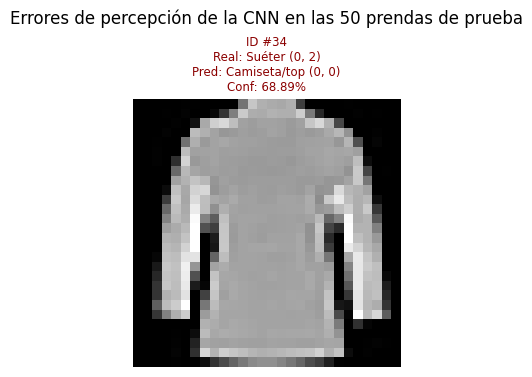

In [4]:
df_errores = df_50[df_50["es_error"]].copy().reset_index(drop=True)
print(f"Total de errores detectados en las 50 prendas: {len(df_errores)}")

if len(df_errores) > 0:
    display(df_errores)

    # Mostrar visualmente cada prenda mal clasificada por la CNN
    n_err = len(df_errores)
    cols = min(5, n_err)
    filas = int(np.ceil(n_err / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(3.4 * cols, 3.8 * filas))
    axes = np.atleast_1d(axes).ravel()

    for i, fila_err in df_errores.iterrows():
        id_p = int(fila_err["id_prenda"])
        axes[i].imshow(imagenes_50[id_p], cmap="gray")
        axes[i].set_title(
            f"ID #{id_p}\n"
            f"Real: {fila_err['categoria_real']} {fila_err['estante_real']}\n"
            f"Pred: {fila_err['categoria_predicha']} {fila_err['estante_objetivo']}\n"
            f"Conf: {fila_err['confianza']:.2%}",
            fontsize=8.5,
            color="darkred",
        )
        axes[i].axis("off")

    for j in range(n_err, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Errores de percepción de la CNN en las 50 prendas de prueba", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("No se presentaron errores de clasificación en esta muestra de 50 prendas.")

## 4. Explicación de los errores de la CNN y su efecto en el almacén

1. **Origen visual de las confusiones:** En Fashion-MNIST ($28 \times 28$ en escala de grises), los errores de percepción de la CNN se concentran en categorías superiores con siluetas casi idénticas: principalmente **Camisa**, **Camiseta/top**, **Suéter** y **Abrigo** (y ocasionalmente **Vestido**). Al carecer de color y detalles finos de tela o botones por la baja resolución, prendas con mangas largas o cortes rectos producen mapas de activación similares.
2. **Impacto directo en el entorno `AlmacenStyleBot`:**
   * Como el robot confía en `carga_percibida` para definir el estante objetivo (`entorno.posicion_estante[carga_percibida]`), **un error de la CNN provoca que el robot navegue perfectamente hasta un estante equivocado**.
   * Al colocar la prenda, el almacén evalúa contra `carga_real` y aplica una penalización de **`-8`** en lugar de **`+10`** (una pérdida neta de **18 puntos** por cada error de percepción), registrándolo en `fallos_cnn` y no en `fallos_politica`.
3. **Importancia de la confianza:** Registrar el campo `confianza` en `datos/entrega3/predicciones_50_prendas.csv` permite identificar predicciones dudosas; en una extensión futura del sistema, prendas con confianza baja podrían enviarse directamente a revisión manual para evitar colocaciones erróneas.
4. **Verificación de reglas del protocolo:** Se utilizó `modelos/stylebot_cnn_final.keras` completamente congelado (`trainable = False`), conservando `semilla_demo = 2026`, `prendas_demo = 50` y el mapeo oficial de estantes definido en `datos/entrega3/protocolo_entrega3.json`.